# Diagnóstico de los modelos finales en el test

Los modelos finales de la 2.2 (YOLOv11n y YOLOv11s, 3 semillas cada uno) se ajustaron y se eligieron con `train` y `valid`. Este notebook los aplica por primera vez al **test de `Data_final`** (70 imágenes de 3 lotes de captura que no intervinieron en ninguna decisión) para identificar qué problemas tienen antes de la evaluación de la 2.3:

1. **Rendimiento:** cuánto rinden en el test frente a `valid` y de qué depende la diferencia.
2. **Tipo de error:** si fallan al detectar, al contar, al clasificar o al ajustar la caja.
3. **Dónde fallan:** qué subtipos y qué lotes concentran los errores, y si los errores son sistemáticos.
4. **Confianza:** si la confianza de una detección distingue los aciertos de los errores.
5. **Objetos que no son maíz:** si detectan como grano las impurezas inorgánicas y orgánicas. Para esto se usan las imágenes del dataset que solo contienen impurezas, retiradas en el OE1 y nunca vistas por los modelos. La clase de otras semillas no se incluye: se descartó en el OE1 por salir del objetivo.

**Criterios:**
- Las métricas de aplicación se calculan con la configuración final de cada modelo: el umbral de conteo de `configuracion_final.json` y NMS agnóstico a la clase.
- Un grano está **detectado** si una predicción lo cubre con IoU ≥ 0.5. Está **acertado** si, además, la clase binaria es la correcta.
- Una predicción **sobrante** no tiene grano emparejado. Es **de fondo** si su IoU con todo grano anotado es menor que 0.1.
- Un error es **sistemático** si lo cometen las 6 corridas.

El diagnóstico no entrena ni cambia los modelos.

In [1]:
import json
import os
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

os.environ['YOLO_VERBOSE'] = 'False'   # sin barras de progreso de Ultralytics
from ultralytics import YOLO

import comun_oe2 as E

C = E.C
C.estilo()
RAIZ = Path.cwd()
SALIDA = RAIZ / 'salida' / '2.2b_diagnostico_test'
CFG = E.config_final()
ETIQUETA = {'yolo11n': 'YOLOv11n', 'yolo11s': 'YOLOv11s'}
CLASE = {0: 'Healthy', 1: 'Defect'}
TEST = sorted((E.FINAL / 'test' / 'images').glob('*.jpg'))
for m, c in CFG.items():
    print(f"{ETIQUETA[m]}: umbral de conteo {c['conf_conteo']}, {len(c['pesos'])} pesos")

YOLOv11n: umbral de conteo 0.397, 3 pesos
YOLOv11s: umbral de conteo 0.457, 3 pesos


## 1. Rendimiento: `valid` frente a test

Cada `best.pt` se evalúa en `valid` y en el test con el validador de Ultralytics (1280 px, en local y en las mismas condiciones). Media ± desviación de las 3 semillas.

In [2]:
filas = []
for modelo, c in CFG.items():
    for pesos in c['pesos']:
        m = YOLO(str(pesos))
        for split in ('val', 'test'):
            v = m.val(data=str(E.FINAL / 'data.yaml'), split=split, imgsz=E.IMGSZ, batch=4, plots=False, verbose=False,
                      project=str(E.TRABAJO), name='val_diagnostico', exist_ok=True)
            filas.append({'modelo': ETIQUETA[modelo], 'split': 'valid' if split == 'val' else 'test',
                          'mAP50-95': v.box.map, 'mAP50': v.box.map50, 'mAP75': v.box.map75,
                          'precisión': v.box.mp, 'recall': v.box.mr,
                          'AP50-95 Healthy': v.box.ap[0], 'AP50-95 Defect': v.box.ap[1]})
        C.liberar_gpu(m)
metricas = pd.DataFrame(filas)
display(metricas.groupby(['modelo', 'split'], sort=False).agg(['mean', 'std']).round(4))
media = metricas.groupby(['modelo', 'split'], sort=False).mean().unstack('split')
display((media.xs('test', axis=1, level=1) - media.xs('valid', axis=1, level=1)).round(4).rename_axis('test − valid'))

mAP50-95           mAP50           mAP75         precisión  \
                   mean     std    mean     std    mean     std      mean   
modelo   split                                                              
YOLOv11n valid   0.7127  0.0037  0.9604  0.0075  0.8426  0.0158    0.8632   
         test    0.7976  0.0270  0.9905  0.0008  0.9463  0.0158    0.9698   
YOLOv11s valid   0.7209  0.0053  0.9580  0.0056  0.8562  0.0080    0.8833   
         test    0.8015  0.0206  0.9871  0.0017  0.9312  0.0196    0.9422   

                        recall         AP50-95 Healthy         AP50-95 Defect  \
                   std    mean     std            mean     std           mean   
modelo   split                                                                  
YOLOv11n valid  0.0222  0.9211  0.0089          0.7050  0.0028         0.7204   
         test   0.0128  0.9696  0.0078          0.7832  0.0552         0.8120   
YOLOv11s valid  0.0098  0.9107  0.0118          0.7323  0.0145         0.7095   
         test   0.0246  0.9641  0.0042          0.8108  0.0502         0.7921   

                        
                   std  
modelo   split          
YOLOv11n valid  0.0071  
         test   0.0109  
YOLOv11s valid  0.0250  
         test   0.0089

,mAP50-95,mAP50,mAP75,precisión,recall,AP50-95 Healthy,AP50-95 Defect
test − valid,,,,,,,
YOLOv11n,0.0849,0.0301,0.1037,0.1066,0.0485,0.0782,0.0916
YOLOv11s,0.0806,0.0291,0.0750,0.0589,0.0534,0.0785,0.0827


**Composición de los conjuntos.** Las métricas dependen de qué imágenes contiene cada conjunto: una bandeja con un solo subtipo es más fácil que una mezclada.

In [3]:
def composicion(split):
    filas = []
    for p in sorted((E.FINAL / split / 'images').glob('*.jpg')):
        _, cajas, _, sub = E.cargar(p.stem, split)
        filas.append({'conjunto': split, 'lote': E.LOTE_CAPTURA[p.stem], 'granos': len(sub), 'varios subtipos': len(set(sub)) > 1,
                      'lado del grano (px)': np.median(np.sqrt((cajas[:, 2] - cajas[:, 0]) * (cajas[:, 3] - cajas[:, 1]))),
                      'subtipos': {E.NOMBRE[s] for s in sub}})
    return pd.DataFrame(filas)

comp = pd.concat([composicion(s) for s in ('train', 'valid', 'test')], ignore_index=True)
display(comp.groupby('conjunto', sort=False).agg(imágenes=('lote', 'size'), lotes=('lote', 'nunique'),
                                                 granos_por_imagen=('granos', 'median'),
                                                 con_varios_subtipos=('varios subtipos', 'mean'),
                                                 lado_del_grano=('lado del grano (px)', 'median')).round(2))
t = comp[comp.conjunto == 'test']
display(t.groupby('lote').agg(imágenes=('granos', 'size'), granos_por_imagen=('granos', 'median'),
                              con_varios_subtipos=('varios subtipos', 'mean'),
                              subtipos=('subtipos', lambda s: ', '.join(sorted(set().union(*s))))).round(2))

,imágenes,lotes,granos_por_imagen,con_varios_subtipos,lado_del_grano
conjunto,,,,,
train,345,17,30.0,0.11,52.05
valid,98,5,30.0,0.22,64.37
test,70,3,30.0,0.06,49.83


,imágenes,granos_por_imagen,con_varios_subtipos,subtipos
lote,,,,
tiempo_010,43,30.0,0.00,"Healthy, Shriveled"
tiempo_011,15,30.0,0.00,Fungus
tiempo_015,12,60.0,0.33,"Broken, Damage, Fungus, Healthy, Immature, Shr..."


## 2. Tipo de error: detección, conteo y clasificación

Para cada modelo y semilla: estado de cada grano anotado, predicciones sobrantes y error de conteo por imagen.

In [4]:
granos, sobrantes, conteo = [], [], []
for modelo, c in CFG.items():
    for pesos in c['pesos']:
        semilla = pesos.parent.parent.name.split('_s')[-1].split('_')[0]
        pred = E.predecir(pesos, TEST, c['conf_conteo'])
        g, s = E.diagnosticar(pred)
        granos.append(g.assign(modelo=ETIQUETA[modelo], semilla=semilla))
        sobrantes.append(s.assign(modelo=ETIQUETA[modelo], semilla=semilla))
        n_gt = g.groupby('stem').size()
        conteo.append(pd.DataFrame({'stem': n_gt.index, 'lote': [E.LOTE_CAPTURA[x] for x in n_gt.index], 'granos': n_gt.values,
                                    'predichos': [len(pred[x][0]) for x in n_gt.index]}).assign(modelo=ETIQUETA[modelo], semilla=semilla))
granos, sobrantes, conteo = (pd.concat(x, ignore_index=True) for x in (granos, sobrantes, conteo))
conteo['error'] = conteo['predichos'] - conteo['granos']

por_corrida = granos.groupby(['modelo', 'semilla']).estado.value_counts().unstack(fill_value=0)
por_corrida['sobrantes sobre un grano'] = sobrantes[sobrantes.tipo == 'sobre un grano'].groupby(['modelo', 'semilla']).size()
por_corrida['sobrantes de fondo'] = sobrantes[sobrantes.tipo == 'fondo'].groupby(['modelo', 'semilla']).size()
por_corrida = por_corrida.fillna(0).astype(int)
por_corrida['MAE de conteo'] = conteo.groupby(['modelo', 'semilla']).error.apply(lambda e: e.abs().mean()).round(3)
por_corrida['error con signo'] = conteo.groupby(['modelo', 'semilla']).error.mean().round(3)
print(f"{granos.groupby(['modelo', 'semilla']).size().iloc[0]} granos anotados en {len(TEST)} imágenes")
display(por_corrida)

2467 granos anotados en 70 imágenes


estado            acierto  clase cambiada  no detectado  \
modelo   semilla                                          
YOLOv11n 28          2385              80             2   
         42          2376              71            20   
         7           2415              49             3   
YOLOv11s 28          2388              76             3   
         42          2339             125             3   
         7           2406              60             1   

estado            sobrantes sobre un grano  sobrantes de fondo  MAE de conteo  \
modelo   semilla                                                                
YOLOv11n 28                              4                   0          0.086   
         42                              4                   4          0.343   
         7                               4                   0          0.071   
YOLOv11s 28                              1                   0          0.057   
         42                              0                   2          0.071   
         7                               6                   1          0.114   

estado            error con signo  
modelo   semilla                   
YOLOv11n 28                 0.029  
         42                -0.171  
         7                  0.014  
YOLOv11s 28                -0.029  
         42                -0.014  
         7                  0.086

### 2.1. Clasificación por subtipo

Fracción de granos de cada subtipo acertados, con la clase binaria cambiada o no detectados (media de las 3 semillas). `Healthy` e `Immature` forman la clase `Healthy`; el resto, `Defect`.

estado     acierto          clase cambiada          no detectado           \
modelo    YOLOv11n YOLOv11s       YOLOv11n YOLOv11s     YOLOv11n YOLOv11s   
subtipo                                                                     
Broken       1.000    1.000          0.000    0.000        0.000    0.000   
Damage       0.996    0.996          0.000    0.000        0.004    0.004   
Fungus       1.000    1.000          0.000    0.000        0.000    0.000   
Shriveled    0.990    0.970          0.006    0.027        0.004    0.003   
Weeveled     0.973    0.969          0.015    0.031        0.011    0.000   
Healthy      0.937    0.948          0.058    0.051        0.005    0.000   
Immature     0.978    0.861          0.022    0.139        0.000    0.000   

estado      granos           
modelo    YOLOv11n YOLOv11s  
subtipo                      
Broken         121      121  
Damage          92       92  
Fungus         456      456  
Shriveled      580      580  
Weeveled        87       87  
Healthy       1009     1009  
Immature       122      122

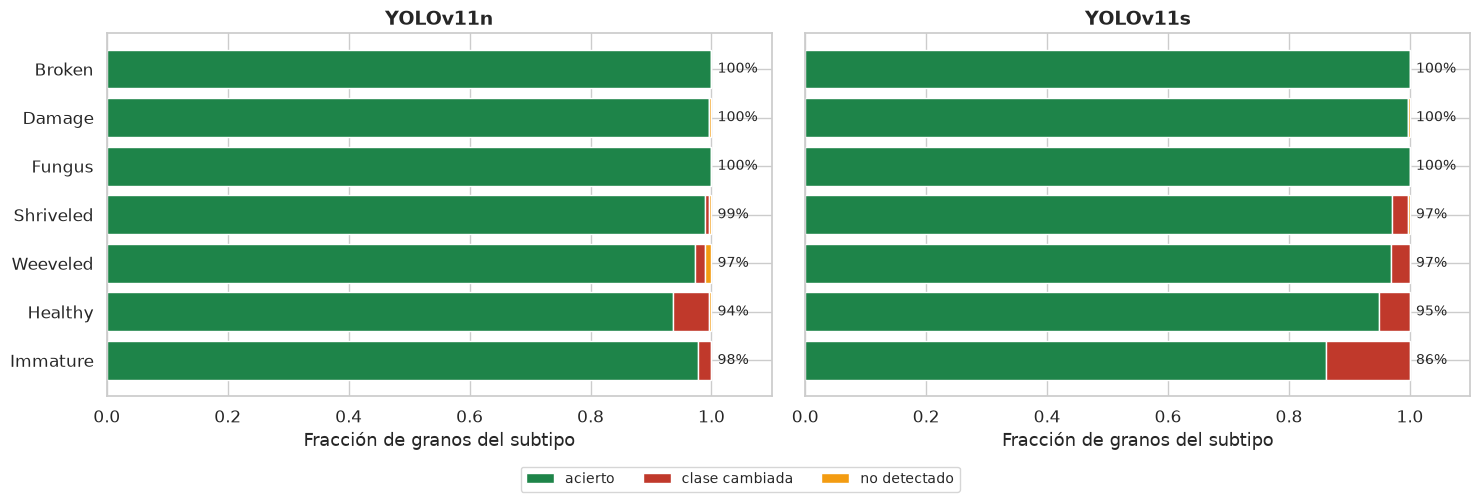

In [5]:
ORDEN = ['Broken', 'Damage', 'Fungus', 'Shriveled', 'Weeveled', 'Healthy', 'Immature']
ESTADOS = {'acierto': E.OK, 'clase cambiada': E.MAL, 'no detectado': '#F39C12'}
frac = (granos.groupby(['modelo', 'subtipo']).estado.value_counts(normalize=True).unstack(fill_value=0)
        .reindex(columns=list(ESTADOS), fill_value=0))
n_sub = granos[granos.semilla == granos.semilla.iloc[0]].groupby(['modelo', 'subtipo']).size()
display(frac.round(3).assign(granos=n_sub).unstack('modelo').reindex(ORDEN))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, modelo in zip(axes, ETIQUETA.values()):
    f = frac.loc[modelo].reindex(ORDEN)
    izq = np.zeros(len(f))
    for estado, color in ESTADOS.items():
        ax.barh(ORDEN[::-1], f[estado].values[::-1], left=izq[::-1], color=color, label=estado)
        izq += f[estado].values
    for i, s in enumerate(ORDEN[::-1]):
        ax.text(1.01, i, f"{f.loc[s, 'acierto']:.0%}", va='center', fontsize=10)
    ax.set_xlim(0, 1.1); ax.set_title(modelo); ax.set_xlabel('Fracción de granos del subtipo')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.06), fontsize=10)
C.guardar(SALIDA, 'estado_por_subtipo.png')

### 2.2. Ajuste de las cajas

El mAP50-95 promedia la precisión con IoU de 0.50 a 0.95, así que también mide cuánto se ajusta cada caja al grano. Se analiza el IoU entre cada grano detectado y su predicción.

media          IoU ≥ 0.75          IoU ≥ 0.90         
modelo    YOLOv11n YOLOv11s   YOLOv11n YOLOv11s   YOLOv11n YOLOv11s
subtipo                                                            
Broken       0.917    0.918      1.000    1.000      0.711    0.730
Damage       0.928    0.925      0.996    0.985      0.844    0.836
Fungus       0.929    0.924      0.999    0.999      0.849    0.800
Shriveled    0.866    0.851      0.920    0.837      0.381    0.374
Weeveled     0.932    0.933      1.000    1.000      0.872    0.847
Healthy      0.906    0.911      0.991    0.997      0.637    0.670
Immature     0.835    0.861      0.833    0.828      0.260    0.478

,media,mediana,IoU ≥ 0.75,IoU ≥ 0.90
modelo,,,,
YOLOv11n,0.900,0.916,0.969,0.617
YOLOv11s,0.899,0.916,0.951,0.631


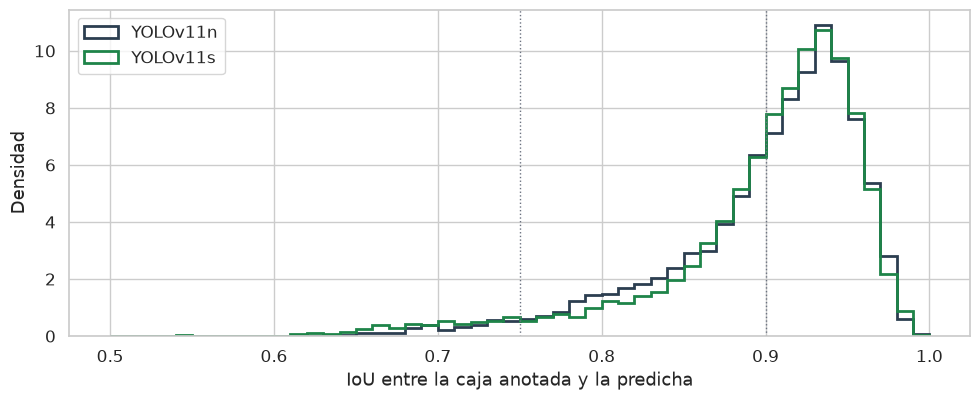

In [6]:
det = granos[granos.estado != 'no detectado']
ajuste = det.groupby(['modelo', 'subtipo']).iou.agg(media='mean', **{'IoU ≥ 0.75': lambda x: (x >= 0.75).mean(),
                                                                   'IoU ≥ 0.90': lambda x: (x >= 0.90).mean()})
display(ajuste.unstack('modelo').reindex(ORDEN).round(3))
display(det.groupby('modelo').iou.agg(media='mean', mediana='median', **{'IoU ≥ 0.75': lambda x: (x >= 0.75).mean(),
                                                                         'IoU ≥ 0.90': lambda x: (x >= 0.90).mean()}).round(3))

fig, ax = plt.subplots(figsize=(10, 4.2))
for modelo, color in zip(ETIQUETA.values(), (E.NEUTRO, E.OK)):
    ax.hist(det[det.modelo == modelo].iou, bins=np.linspace(0.5, 1, 51), histtype='step', lw=2, density=True, color=color, label=modelo)
for u in (0.75, 0.9):
    ax.axvline(u, color=E.GRIS, ls=':', lw=1)
ax.set_xlabel('IoU entre la caja anotada y la predicha'); ax.set_ylabel('Densidad'); ax.legend()
C.guardar(SALIDA, 'ajuste_cajas.png')

### 2.3. Confianza de aciertos y errores

Si los errores de clase tuvieran una confianza claramente menor que los aciertos, podrían señalarse para revisión manual.

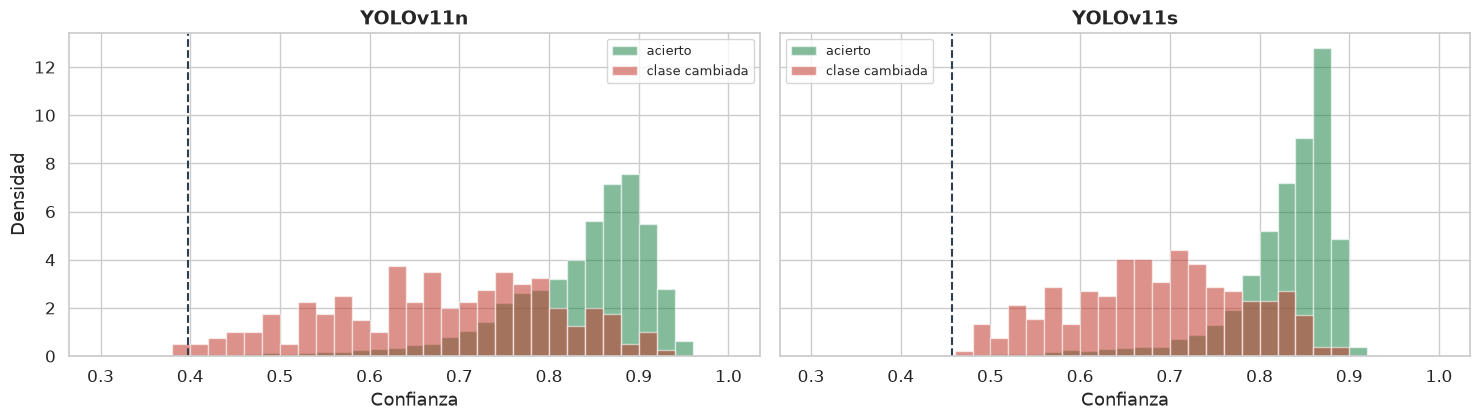

estado,acierto,clase cambiada
modelo,,
YOLOv11n,0.856,0.688
YOLOv11s,0.846,0.689


,modelo,confianza menor que,errores de clase señalados,aciertos señalados
0,YOLOv11n,0.6,0.280,0.025
1,YOLOv11n,0.7,0.530,0.072
2,YOLOv11s,0.6,0.203,0.014
3,YOLOv11s,0.7,0.529,0.047


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
bins = np.linspace(0.3, 1, 36)
filas = []
for ax, (modelo, c) in zip(axes, CFG.items()):
    d = det[det.modelo == ETIQUETA[modelo]]
    for estado, color in (('acierto', E.OK), ('clase cambiada', E.MAL)):
        ax.hist(d[d.estado == estado].conf, bins=bins, density=True, alpha=0.55, color=color, label=estado)
    ax.axvline(c['conf_conteo'], color=E.NEUTRO, ls='--', lw=1.5)
    ax.set_title(ETIQUETA[modelo]); ax.set_xlabel('Confianza'); ax.legend(fontsize=9)
    for u in (0.6, 0.7):
        filas.append({'modelo': ETIQUETA[modelo], 'confianza menor que': u,
                      'errores de clase señalados': (d[d.estado == 'clase cambiada'].conf < u).mean(),
                      'aciertos señalados': (d[d.estado == 'acierto'].conf < u).mean()})
axes[0].set_ylabel('Densidad')
C.guardar(SALIDA, 'confianza_errores.png')
display(det.groupby(['modelo', 'estado']).conf.median().unstack().round(3))
display(pd.DataFrame(filas).round(3))

## 3. Dónde fallan: lotes y errores sistemáticos

In [8]:
por_lote = (granos.groupby(['lote', 'modelo']).estado.value_counts(normalize=True).unstack(fill_value=0)
            .reindex(columns=list(ESTADOS), fill_value=0).round(3))
por_lote['MAE de conteo'] = conteo.groupby(['lote', 'modelo']).error.apply(lambda e: e.abs().mean()).round(3)
display(por_lote)

errores = granos[granos.estado != 'acierto']
veces = errores.groupby(['stem', 'grano']).size()
sistematicos = (errores.set_index(['stem', 'grano']).loc[veces[veces == 6].index]
                .reset_index().drop_duplicates(['stem', 'grano']))
total = granos.groupby(['modelo', 'semilla']).size().iloc[0]
print(f'Granos con algún error en alguna corrida: {len(veces)} de {total}; sistemáticos (6 de 6): {len(sistematicos)}')
display(pd.crosstab([sistematicos['lote'], sistematicos['subtipo']], sistematicos['estado']).rename_axis(None, axis=1))

estado               acierto  clase cambiada  no detectado  MAE de conteo
lote       modelo                                                        
tiempo_010 YOLOv11n    0.983           0.013         0.004          0.109
           YOLOv11s    0.976           0.023         0.001          0.031
tiempo_011 YOLOv11n    1.000           0.000         0.000          0.022
           YOLOv11s    1.000           0.000         0.000          0.000
tiempo_015 YOLOv11n    0.927           0.068         0.005          0.556
           YOLOv11s    0.919           0.079         0.002          0.361

Granos con algún error en alguna corrida: 241 de 2467; sistemáticos (6 de 6): 25


clase cambiada  no detectado
lote       subtipo                                
tiempo_015 Healthy                24             0
           Shriveled               0             1

### 3.1. Galería de errores sistemáticos

Recortes de granos que las 6 corridas clasifican mal, hasta 12 por subtipo. Caja: la anotación; título: subtipo anotado → clase predicha (la de YOLOv11s, semilla 42).

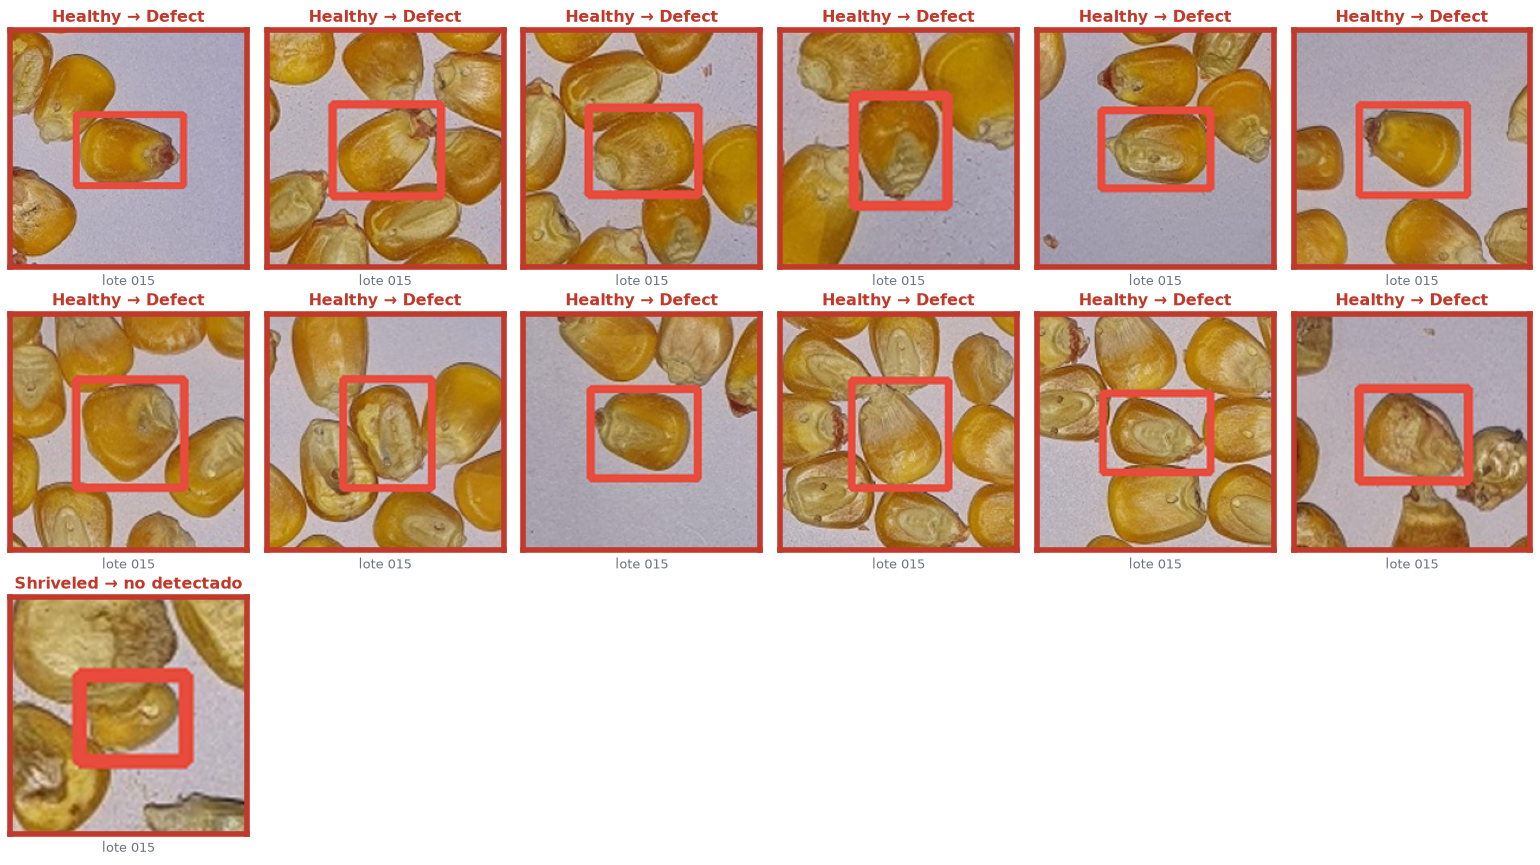

In [9]:
def galeria(filas, titulo_de, archivo, columnas=6, lado=200, split='test'):
    filas = list(filas)
    n = len(filas); r = int(np.ceil(n / columnas))
    fig, axes = plt.subplots(r, columnas, figsize=(2.6 * columnas, 2.9 * r))
    for ax in np.ravel(axes)[n:]:
        ax.axis('off')
    cache = {}
    for ax, f in zip(np.ravel(axes), filas):
        if f['stem'] not in cache:
            cache[f['stem']] = (cv2.cvtColor(cv2.imread(str(f['ruta'])), cv2.COLOR_BGR2RGB) if 'ruta' in f
                                else E.cargar(f['stem'], split)[0])
        b = np.asarray(f['caja'], float); L = int(max(b[2] - b[0], b[3] - b[1]) * 2.2)
        rec, _ = E.recorte(E.dibujar(cache[f['stem']], [b], E.CAJA_MAL, 3), ((b[0] + b[2]) / 2, (b[1] + b[3]) / 2), L, lado)
        E.mostrar(ax, rec, *titulo_de(f), estado='mal')
    C.guardar(SALIDA, archivo)

ref = granos[(granos.modelo == 'YOLOv11s') & (granos.semilla == '42')].set_index(['stem', 'grano'])['clase_pred']
muestra = (sistematicos.assign(pred=[ref.get((s, g)) for s, g in zip(sistematicos.stem, sistematicos.grano)])
           .sort_values(['subtipo', 'lote']).groupby('subtipo', group_keys=False).head(12))
galeria(muestra.to_dict('records'),
        lambda f: (f"{f['subtipo']} → {CLASE[int(f['pred'])] if pd.notna(f['pred']) else 'no detectado'}",
                   f"lote {f['lote'].split('_')[-1]}"),
        'errores_sistematicos.png')

### 3.2. Imagen con más errores

La imagen del test con más errores sistemáticos, con las predicciones de YOLOv11s (semilla 42). Verde: acierto; rojo: clase cambiada; naranja: no detectado; azul: predicción sobrante.

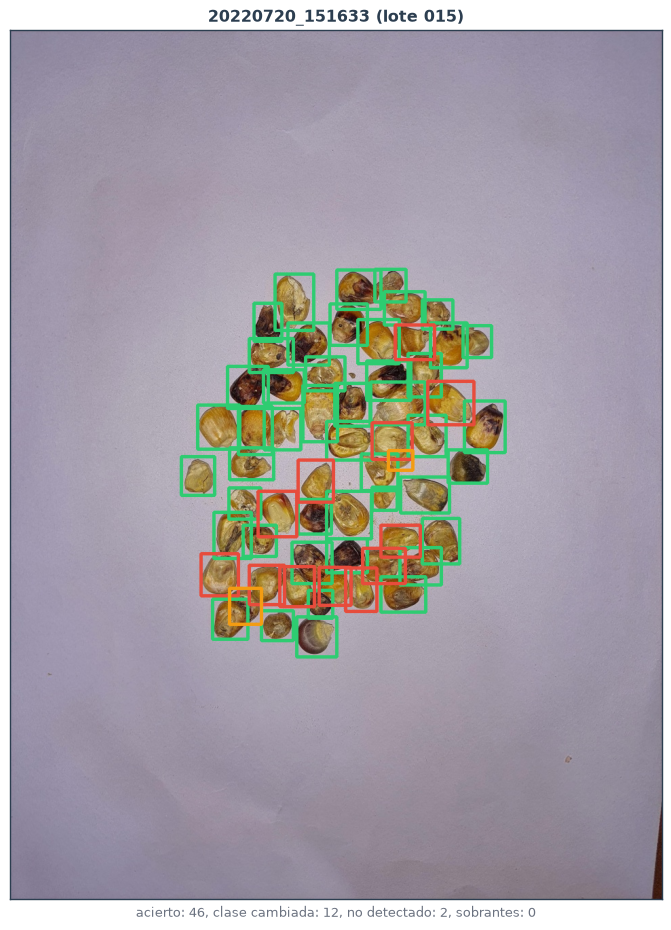

In [10]:
peor = sistematicos.stem.value_counts().index[0]
img = E.cargar(peor, 'test')[0]
g = granos[(granos.stem == peor) & (granos.modelo == 'YOLOv11s') & (granos.semilla == '42')]
s = sobrantes[(sobrantes.stem == peor) & (sobrantes.modelo == 'YOLOv11s') & (sobrantes.semilla == '42')]
vista = img.copy()
for estado, color in (('acierto', E.CAJA_OK), ('clase cambiada', E.CAJA_MAL), ('no detectado', (243, 156, 18))):
    if (g.estado == estado).any():
        vista = E.dibujar(vista, np.stack(g[g.estado == estado].caja.values), color, 3)
if len(s):
    vista = E.dibujar(vista, np.stack(s.caja.values), E.CAJA_B, 3)
fig, ax = plt.subplots(figsize=(12, 9.5))
E.mostrar(ax, vista, f"{peor[:15]} (lote {E.LOTE_CAPTURA[peor].split('_')[-1]})",
          ', '.join(f'{k}: {v}' for k, v in g.estado.value_counts().items()) + f', sobrantes: {len(s)}')
C.guardar(SALIDA, 'peor_imagen_test.png')

## 4. Objetos que no son maíz

Las imágenes que solo contienen impurezas inorgánicas u orgánicas se llevan a 1280 px con el mismo letterbox de `Data_final`. Cada predicción en ellas es un falso positivo. Se mide:
- cuántas impurezas se detectan como grano (IoU ≥ 0.5) y con qué clase;
- si el umbral de confianza las separa de los granos reales.

In [11]:
RUTAS, ANOT = E.imagenes_impurezas(E.TRABAJO / 'impurezas')
tipo_img = {s: E.IMPUREZAS[int(c[0])] for s, (_, c) in ANOT.items()}
print(Counter(tipo_img.values()), '|', sum(len(c) for _, c in ANOT.values()), 'objetos anotados')

objetos, detecciones = [], []
for modelo, c in CFG.items():
    for pesos in c['pesos']:
        semilla = pesos.parent.parent.name.split('_s')[-1].split('_')[0]
        pred = E.predecir(pesos, RUTAS, c['conf_conteo'])
        for stem, (pb, pc, pf) in pred.items():
            gt, cls = ANOT[stem]
            pares, _ = E.emparejar(gt, pb)
            for o in range(len(gt)):
                q = pares.get(o)
                objetos.append({'modelo': ETIQUETA[modelo], 'semilla': semilla, 'stem': stem, 'tipo': E.IMPUREZAS[int(cls[o])],
                                'detectado': q is not None, 'clase_pred': None if q is None else CLASE[int(pc[q])],
                                'conf': None if q is None else float(pf[q]), 'caja': gt[o]})
            detecciones.append({'modelo': ETIQUETA[modelo], 'semilla': semilla, 'stem': stem, 'tipo': tipo_img[stem],
                                'objetos': len(gt), 'detecciones': len(pb)})
objetos, detecciones = pd.DataFrame(objetos), pd.DataFrame(detecciones)

t = detecciones.groupby(['modelo', 'tipo']).agg(imágenes=('stem', 'nunique'), objetos_por_imagen=('objetos', 'mean'),
                                                 detecciones_por_imagen=('detecciones', 'mean'))
t['detectadas como grano'] = objetos.groupby(['modelo', 'tipo']).detectado.mean()
t['de ellas, como Healthy'] = objetos[objetos.detectado].groupby(['modelo', 'tipo']).clase_pred.apply(lambda x: (x == 'Healthy').mean())
display(t.round(3))
tot = detecciones.groupby(['modelo', 'semilla']).detecciones.sum().groupby('modelo').agg(['mean', 'std'])
display(tot.round(1).rename(columns={'mean': 'falsos positivos (media)', 'std': 'desviación'}))

Counter({'Inorganic': 76, 'Organic': 68}) | 5072 objetos anotados


imágenes  objetos_por_imagen  detecciones_por_imagen  \
modelo   tipo                                                              
YOLOv11n Inorganic        76              34.868                  35.601   
         Organic          68              35.618                  43.583   
YOLOv11s Inorganic        76              34.868                  34.833   
         Organic          68              35.618                  37.157   

                    detectadas como grano  de ellas, como Healthy  
modelo   tipo                                                      
YOLOv11n Inorganic                  0.984                   0.001  
         Organic                    0.953                   0.001  
YOLOv11s Inorganic                  0.979                   0.010  
         Organic                    0.898                   0.003

,falsos positivos (media),desviación
modelo,,
YOLOv11n,5669.3,94.4
YOLOv11s,5174.0,42.2


### 4.1. Confianza: impurezas frente a granos

Confianza de las impurezas detectadas como grano y de los granos detectados del test (todas las semillas). La línea marca el umbral de conteo; el título indica qué fracción de las impurezas detectadas seguiría por encima de cada umbral.

YOLOv11n: mediana de confianza, granos 0.85, impurezas 0.81
YOLOv11s: mediana de confianza, granos 0.84, impurezas 0.80


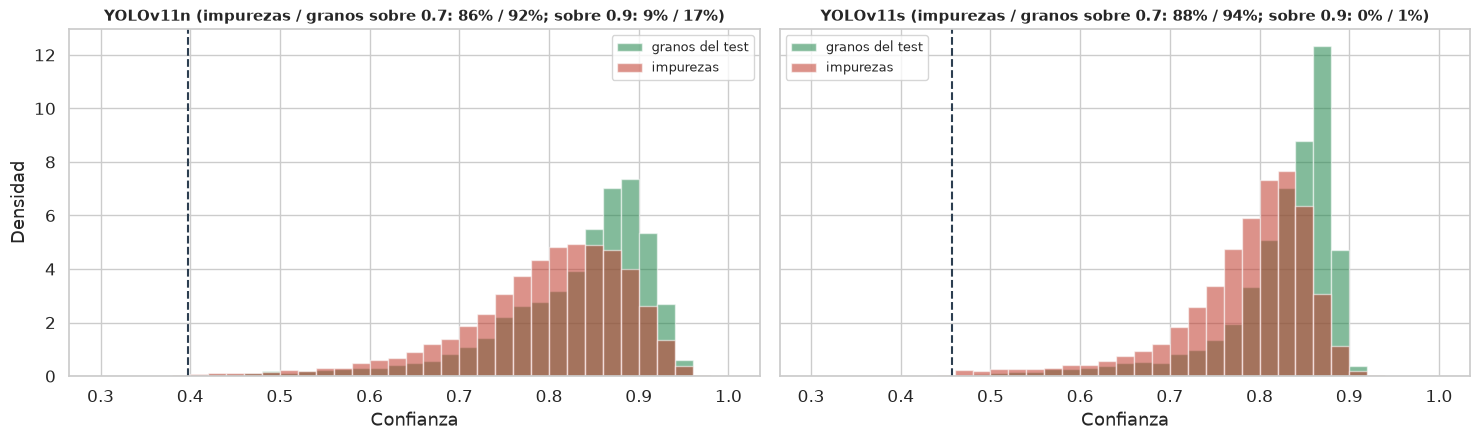

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
bins = np.linspace(0.3, 1, 36)
for ax, (modelo, c) in zip(axes, CFG.items()):
    et = ETIQUETA[modelo]
    imp = objetos[(objetos.modelo == et) & objetos.detectado].conf
    gr = det[det.modelo == et].conf
    ax.hist(gr, bins=bins, density=True, alpha=0.55, color=E.OK, label='granos del test')
    ax.hist(imp, bins=bins, density=True, alpha=0.55, color=E.MAL, label='impurezas')
    ax.axvline(c['conf_conteo'], color=E.NEUTRO, lw=1.5, ls='--')
    ax.set_title(f"{et} (impurezas / granos sobre 0.7: {(imp >= 0.7).mean():.0%} / {(gr >= 0.7).mean():.0%};"
                 f" sobre 0.9: {(imp >= 0.9).mean():.0%} / {(gr >= 0.9).mean():.0%})", fontsize=10.5)
    ax.set_xlabel('Confianza'); ax.legend(fontsize=9)
    print(f'{et}: mediana de confianza, granos {gr.median():.2f}, impurezas {imp.median():.2f}')
axes[0].set_ylabel('Densidad')
C.guardar(SALIDA, 'confianza_impurezas.png')

### 4.2. Ejemplos

Impurezas detectadas como grano por YOLOv11s (semilla 42), de la más a la menos confiada, y una imagen completa de cada tipo.

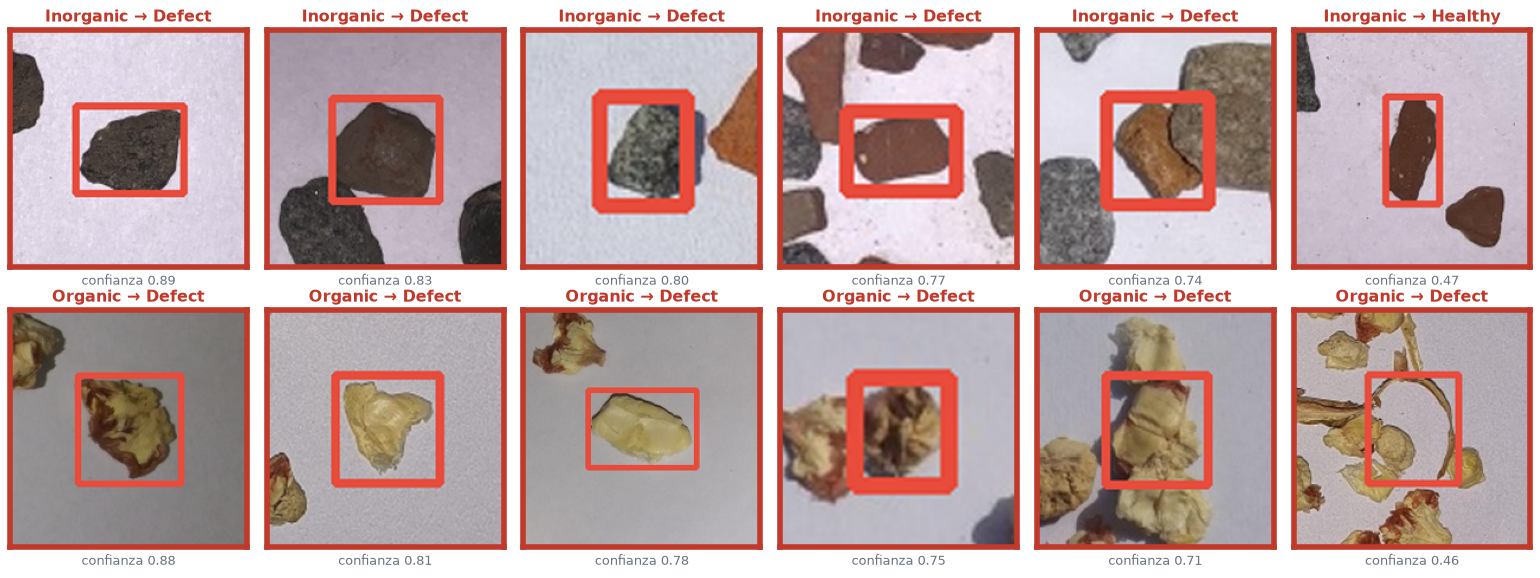

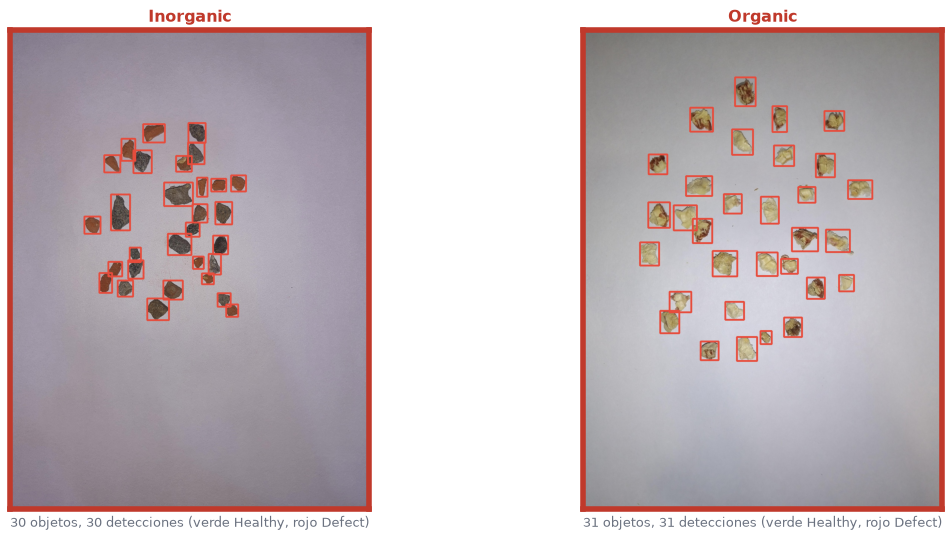

In [13]:
ruta = {p.stem: p for p in RUTAS}
m = objetos[(objetos.modelo == 'YOLOv11s') & (objetos.semilla == '42') & objetos.detectado]
m = m.assign(ruta=m.stem.map(ruta)).sort_values('conf', ascending=False)
muestra = pd.concat([d.iloc[np.linspace(0, len(d) - 1, 6).astype(int)] for _, d in m.groupby('tipo')])
galeria(muestra.to_dict('records'), lambda f: (f"{f['tipo']} → {f['clase_pred']}", f"confianza {f['conf']:.2f}"),
        'impurezas_detectadas.png')

pesos = CFG['yolo11s']['pesos'][0]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, tipo in zip(axes, E.IMPUREZAS.values()):
    d = detecciones[(detecciones.tipo == tipo) & (detecciones.modelo == 'YOLOv11s') & (detecciones.semilla == '42')]
    stem = d.sort_values('detecciones').stem.iloc[len(d) // 2]   # imagen con el número mediano de detecciones
    pb, pc, _ = E.predecir(pesos, [ruta[stem]], CFG['yolo11s']['conf_conteo'])[stem]
    img = cv2.cvtColor(cv2.imread(str(ruta[stem])), cv2.COLOR_BGR2RGB)
    vista = E.dibujar(E.dibujar(img, pb[pc == 0], E.CAJA_OK, 4), pb[pc == 1], E.CAJA_MAL, 4)
    E.mostrar(ax, vista, tipo, f'{len(ANOT[stem][0])} objetos, {len(pb)} detecciones (verde Healthy, rojo Defect)', estado='mal')
C.guardar(SALIDA, 'impurezas_imagen.png')